# Interactive NBA Data Explorer

By Julia Rasul

## Setup

This notebook reads cleaned_data.csv, created by [nba_pay_vs_performance.ipynb](nba_pay_vs_performance.ipynb) (540 NBA players from the 2021-22 season) and lets a user explore it through a menu with 5 choices. Each choice shows a table or chart with a short summary written from the data.

In [1]:
# set up
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['text.parse_math'] = False
pd.set_option('display.html.use_mathjax', False)


In [2]:
# read in the csv file

def load_data(file):
    "Reads the cleaned csv and puts binned columns (like salary_tier) in order from lowest to highest"
    df = pd.read_csv(file, index_col=0)
    # a binned column is named after the number column it was made from (salary -> salary_tier)
    for col in df.select_dtypes(exclude='number').columns:
        for num_col in df.select_dtypes('number').columns:
            if col.startswith(num_col + '_'):
                order = df.groupby(col)[num_col].min().sort_values().index
                df[col] = pd.Categorical(df[col], categories=order, ordered=True)
    return df

df = load_data('cleaned_data.csv')

In [3]:
# split info into number and string columns

def find_columns(df):
    "Returns a list of number columns and a list of group columns"
    number_cols = []
    for col in df.select_dtypes('number').columns:
        if df[col].nunique() > 1:
            number_cols.append(col)

    group_cols = []
    for col in df.select_dtypes(exclude='number').columns:
        if df[col].nunique() <= 10:
            group_cols.append(col)
    return number_cols, group_cols

number_cols, group_cols = find_columns(df)
print(f"Number columns: {number_cols}")
print(f"Group columns: {group_cols}")

Number columns: ['games', 'minutes', 'points', 'rebounds', 'assists', 'salary', 'times_injured']
Group columns: ['position', 'draft_round', 'salary_tier']


## Option 1

This choice shows summary statistics for every number column that varies. Its output is shown in the menu demo at the end, so it is not repeated here.

In [4]:
# summary statistics for number columns

def show_summary(df, number_cols):
    display(df[number_cols].describe().transpose().round(2))

    print(f"\nThis table covers {len(number_cols)} number columns for {len(df)} players.")
    for col in number_cols:
        mean = df[col].mean()
        median = df[col].median()
        if mean > median * 1.1:
            print(f"{col}: mean ({mean:,.2f}) is above the median ({median:,.2f}), so some high values pull the average up.")
        elif mean < median * 0.9:
            print(f"{col}: mean ({mean:,.2f}) is below the median ({median:,.2f}), so some low values pull the average down.")
        else:
            print(f"{col}: mean ({mean:,.2f}) and median ({median:,.2f}) are close, so the values are fairly balanced.")

## Option 2

This choice shows the count and percent of players in each group of one group column, with a bar chart.

,count,percent
salary_tier,,
Under $2.5M,252,46.7
$2.5M to $5M,90,16.7
$5M to $15M,103,19.1
$15M to $30M,55,10.2
$30M+,40,7.4


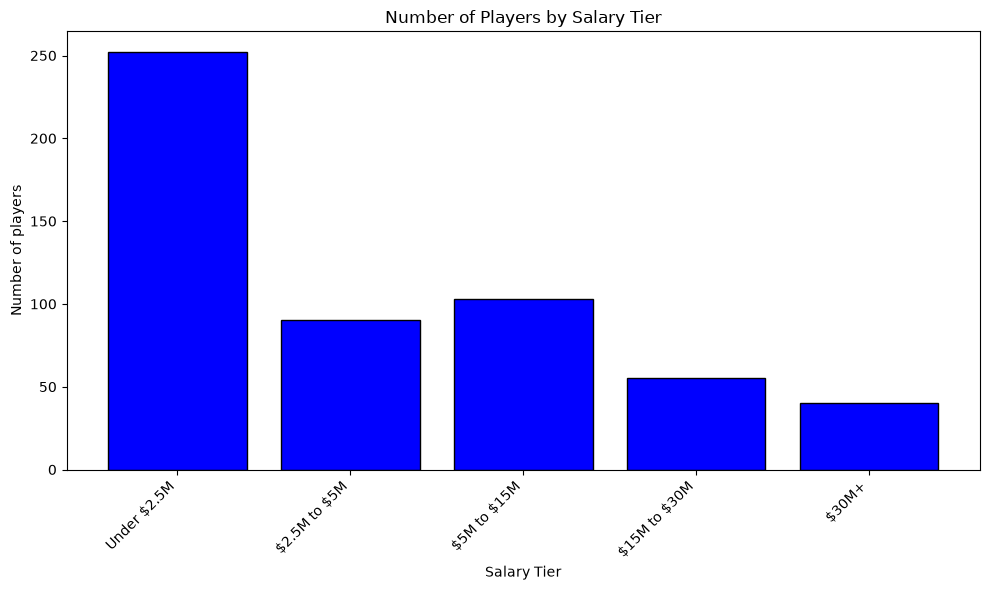

There are 5 groups in salary tier.
The most common is Under $2.5M with 252 player(s) (46.7%).
The least common is $30M+ with 40 player(s) (7.4%).


In [5]:
# counts and bar chart for one group column

def show_counts(df, col):
    label = col.replace('_', ' ')
    counts = df[col].value_counts()
    # keep ordered groups like salary tiers in order from lowest to highest
    if isinstance(df[col].dtype, pd.CategoricalDtype) and df[col].cat.ordered:
        counts = counts.sort_index()
    percent = (counts / len(df) * 100).round(1)
    display(pd.DataFrame({'count': counts, 'percent': percent}))

    plt.figure(figsize=(10, 6))
    plt.bar(counts.index.astype(str), counts.values, color='blue', edgecolor='black')
    plt.title(f"Number of Players by {label.title()}")
    plt.xlabel(label.title())
    plt.ylabel('Number of players')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    print(f"There are {len(counts)} groups in {label}.")
    most = counts.idxmax()
    least = counts.idxmin()
    print(f"The most common is {most} with {counts[most]} player(s) ({percent[most]}%).")
    print(f"The least common is {least} with {counts[least]} player(s) ({percent[least]}%).")

show_counts(df, 'salary_tier')

## Option 3

This choice shows the average of one number column for each group in a group column, with a bar chart.

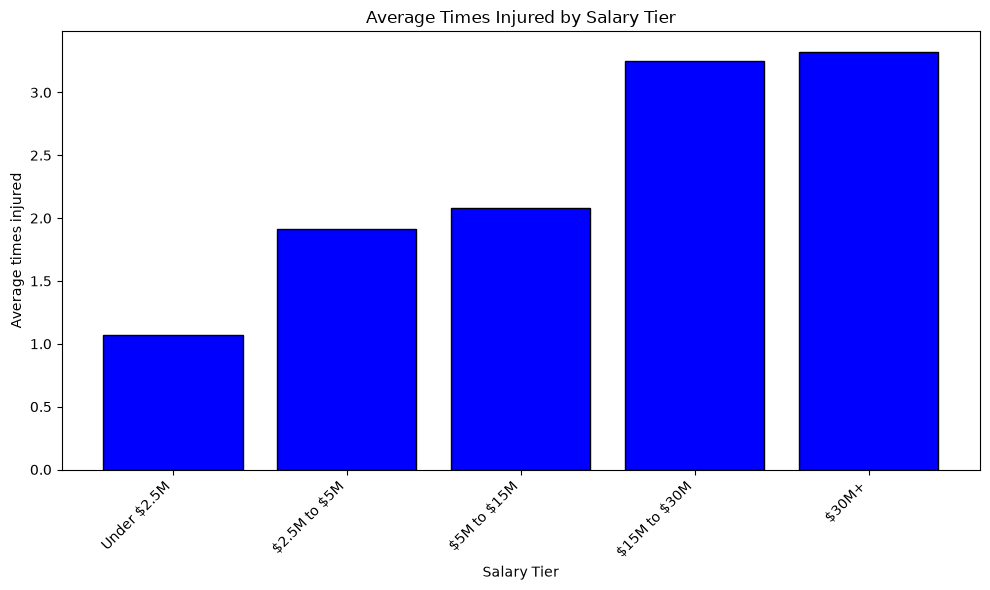

salary tier Under $2.5M: average times injured is 1.07 (252 player(s))
salary tier $2.5M to $5M: average times injured is 1.91 (90 player(s))
salary tier $5M to $15M: average times injured is 2.08 (103 player(s))
salary tier $15M to $30M: average times injured is 3.25 (55 player(s))
salary tier $30M+: average times injured is 3.32 (40 player(s))
The highest average is 3.32 (salary tier $30M+) and the lowest is 1.07 (salary tier Under $2.5M).


In [6]:
# average of a number column for each group

def show_group_average(df, num_col, group_col):
    num_label = num_col.replace('_', ' ')
    group_label = group_col.replace('_', ' ')
    averages = df.groupby(group_col, observed=True)[num_col].mean().round(2)
    # keep ordered groups like salary tiers in order, sort the rest from highest to lowest
    if not (isinstance(df[group_col].dtype, pd.CategoricalDtype) and df[group_col].cat.ordered):
        averages = averages.sort_values(ascending=False)
    sizes = df.groupby(group_col, observed=True)[num_col].count()

    plt.figure(figsize=(10, 6))
    plt.bar(averages.index.astype(str), averages.values, color='blue', edgecolor='black')
    plt.title(f"Average {num_label.title()} by {group_label.title()}")
    plt.xlabel(group_label.title())
    plt.ylabel(f"Average {num_label}")
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

    for group in averages.index:
        print(f"{group_label} {group}: average {num_label} is {averages[group]:,.2f} ({sizes[group]} player(s))")
    print(f"The highest average is {averages.max():,.2f} ({group_label} {averages.idxmax()}) and the lowest is {averages.min():,.2f} ({group_label} {averages.idxmin()}).")
    if sizes.min() < 10:
        print("Some groups have fewer than 10 players, so their averages are less reliable.")

show_group_average(df, 'times_injured', 'salary_tier')

## Option 4

This choice shows a crosstab of any two group columns.

In [7]:
# crosstab of two group columns

def show_crosstab(df, row_col, column_col):
    table = pd.crosstab(df[row_col], df[column_col], margins=True)
    display(table)

    table = table.drop('All').drop(columns='All')
    for group in table.index:
        top = table.loc[group].max()
        winners = table.columns[table.loc[group] == top].tolist()
        print(f"{group}: the most common {column_col.replace('_', ' ')} is {' and '.join(str(w) for w in winners)} ({top} player(s))")

show_crosstab(df, 'salary_tier', 'draft_round')

draft_round,1,2,Undrafted,All
salary_tier,,,,
Under $2.5M,31,84,137,252
$2.5M to $5M,71,11,8,90
$5M to $15M,70,19,14,103
$15M to $30M,39,11,5,55
$30M+,38,2,0,40
All,249,127,164,540


Under $2.5M: the most common draft round is Undrafted (137 player(s))
$2.5M to $5M: the most common draft round is 1 (71 player(s))
$5M to $15M: the most common draft round is 1 (70 player(s))
$15M to $30M: the most common draft round is 1 (39 player(s))
$30M+: the most common draft round is 1 (38 player(s))


## Option 5

This choice shows a scatter plot of two number columns, with each group of a group column shown in its own marker shape and shade of blue, plus the Spearman correlation between the two columns.

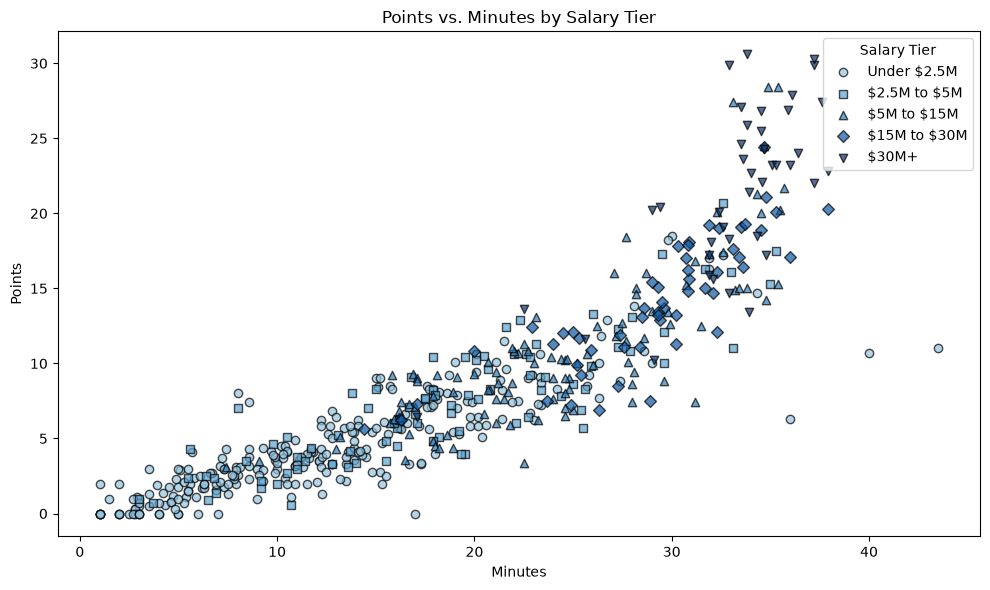

The Spearman correlation between minutes and points is 0.93, a strong positive relationship.
salary tier Under $2.5M: average minutes is 12.80 and average points is 4.55 (252 player(s))
salary tier $2.5M to $5M: average minutes is 18.38 and average points is 7.36 (90 player(s))
salary tier $5M to $15M: average minutes is 24.16 and average points is 10.72 (103 player(s))
salary tier $15M to $30M: average minutes is 28.94 and average points is 13.91 (55 player(s))
salary tier $30M+: average minutes is 33.09 and average points is 21.39 (40 player(s))


In [8]:
# scatter plot of two number columns, split by a group column

def scale_millions(values, label):
    "Shows very large numbers in millions so the axis is easy to read"
    if values.max() >= 1000000:
        return values / 1000000, f"{label} ($ millions)"
    return values, label

def show_scatter(df, x_col, y_col, group_col):
    x_label = x_col.replace('_', ' ')
    y_label = y_col.replace('_', ' ')
    group_label = group_col.replace('_', ' ')
    groups = df[group_col].value_counts().sort_index().index
    markers = ['o', 's', '^', 'D', 'v', 'P', 'X', '*', 'h', '<']
    shades = plt.cm.Blues(np.linspace(0.4, 1, len(groups)))

    x_values, x_axis = scale_millions(df[x_col], x_label.title())
    y_values, y_axis = scale_millions(df[y_col], y_label.title())

    plt.figure(figsize=(10, 6))
    for group, marker, shade in zip(groups, markers, shades):
        in_group = df[group_col] == group
        plt.scatter(x_values[in_group], y_values[in_group], marker=marker, color=shade, edgecolor='black', alpha=0.7, label=str(group))
    plt.title(f"{y_label.title()} vs. {x_label.title()} by {group_label.title()}")
    plt.xlabel(x_axis)
    plt.ylabel(y_axis)
    plt.legend(title=group_label.title())
    plt.tight_layout()
    plt.show()

    corr = df[[x_col, y_col]].corr(method='spearman').iloc[0, 1]
    if abs(corr) >= 0.7:
        strength = 'strong'
    elif abs(corr) >= 0.4:
        strength = 'moderate'
    else:
        strength = 'weak'
    if corr > 0:
        direction = 'positive'
    else:
        direction = 'negative'
    print(f"The Spearman correlation between {x_label} and {y_label} is {corr:.2f}, a {strength} {direction} relationship.")

    for group in groups:
        subset = df[df[group_col] == group]
        print(f"{group_label} {group}: average {x_label} is {subset[x_col].mean():,.2f} and average {y_label} is {subset[y_col].mean():,.2f} ({len(subset)} player(s))")

show_scatter(df, 'minutes', 'points', 'salary_tier')

# Menu

In [9]:
# let the user pick a column, unless one was already given
def pick_column(cols, picked=None):
    if picked in cols:
        return picked
    for idx, col in enumerate(cols):
        print(f"{idx + 1}. {col}")
    answer = input(f"Pick a column (1 to {len(cols)}): ")
    while not answer.isdigit() or int(answer) not in range(1, len(cols) + 1):
        answer = input(f"Please enter only a number from 1 to {len(cols)}: ")
    return cols[int(answer) - 1]

In [10]:
# menu function: asks the user for a choice, or runs the choice it is given

def menu(choice=None, col1=None, col2=None, col3=None, file='cleaned_data.csv'):
    "Interactive explorer for the cleaned NBA data"
    df = load_data(file)
    number_cols, group_cols = find_columns(df)

    if choice is None:
        print("1. Summary statistics for number columns\n2. Counts for a group column\n"
              "3. Average of a number column by group\n4. Crosstab of two group columns\n"
              "5. Scatter plot of two number columns by group")
        choice = input("Enter 1, 2, 3, 4, or 5: ")
    choice = str(choice)

    while not choice.isdigit() or int(choice) not in [1, 2, 3, 4, 5]:
        choice = input("Please enter only the number 1, 2, 3, 4, or 5: ")

    if int(choice) == 1:
        show_summary(df, number_cols)
    elif int(choice) == 2:
        show_counts(df, pick_column(group_cols, col1))
    elif int(choice) == 3:
        show_group_average(df, pick_column(number_cols, col1), pick_column(group_cols, col2))
    elif int(choice) == 4:
        first = pick_column(group_cols, col1)
        others = [col for col in group_cols if col != first]
        show_crosstab(df, first, pick_column(others, col2))
    else:
        x_col = pick_column(number_cols, col1)
        others = [col for col in number_cols if col != x_col]
        show_scatter(df, x_col, pick_column(others, col2), pick_column(group_cols, col3))

## Demo of every menu option

Each cell below calls the menu once and runs one option, so all of the output shows when viewing the notebook. The demos use different column combinations than the examples above. Each option only lists the columns that fit it: number columns must have more than one value, and group columns must have 10 or fewer groups, so columns like draft_year and draft_number are left out.

To use the menu interactively, run `menu()` with no arguments. It asks for a choice and then for each column it needs.

In [11]:
menu(choice=1)

,count,mean,std,min,25%,50%,75%,max
games,540.0,43.24,25.88,1.0,18.00,49.00,67.00,82.0
minutes,540.0,19.05,9.86,1.0,11.00,18.20,27.32,43.5
points,540.0,8.40,6.50,0.0,3.50,7.05,11.30,30.6
rebounds,540.0,3.49,2.44,0.0,1.80,3.00,4.53,14.7
assists,540.0,1.91,1.88,0.0,0.60,1.20,2.60,10.8
salary,540.0,7641741.99,10801261.14,15372.0,939373.75,2777011.00,9706939.00,52938707.0
times_injured,540.0,1.79,2.02,0.0,0.00,1.00,3.00,12.0



This table covers 7 number columns for 540 players.
games: mean (43.24) is below the median (49.00), so some low values pull the average down.
minutes: mean (19.05) and median (18.20) are close, so the values are fairly balanced.
points: mean (8.40) is above the median (7.05), so some high values pull the average up.
rebounds: mean (3.49) is above the median (3.00), so some high values pull the average up.
assists: mean (1.91) is above the median (1.20), so some high values pull the average up.
salary: mean (7,641,741.99) is above the median (2,777,011.00), so some high values pull the average up.
times_injured: mean (1.79) is above the median (1.00), so some high values pull the average up.


,count,percent
position,,
Shooting Guard,135,25.0
Small Forward,101,18.7
Point Guard,97,18.0
Power Forward,96,17.8
Center,95,17.6
Shooting Guard-Small Forward,9,1.7
Point Guard-Shooting Guard,4,0.7
Center-Power Forward,2,0.4
Power Forward-Small Forward,1,0.2


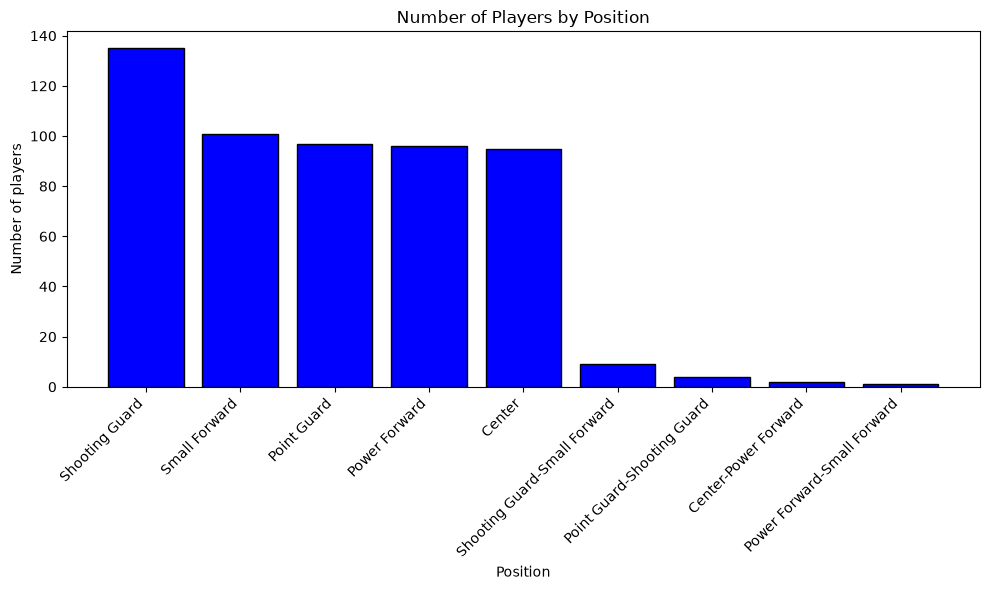

There are 9 groups in position.
The most common is Shooting Guard with 135 player(s) (25.0%).
The least common is Power Forward-Small Forward with 1 player(s) (0.2%).


In [12]:
menu(choice=2, col1='position')

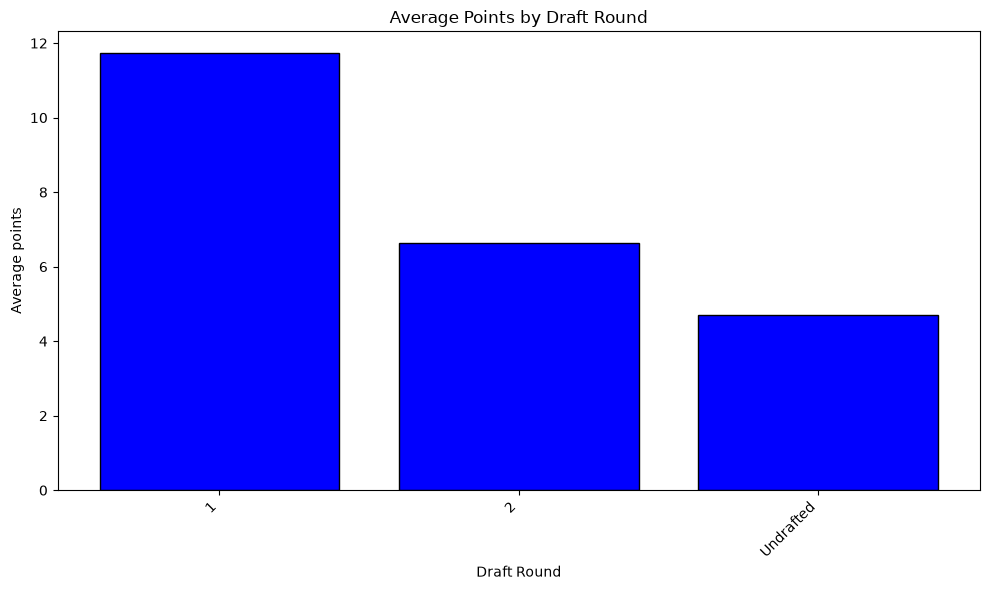

draft round 1: average points is 11.73 (249 player(s))
draft round 2: average points is 6.64 (127 player(s))
draft round Undrafted: average points is 4.70 (164 player(s))
The highest average is 11.73 (draft round 1) and the lowest is 4.70 (draft round Undrafted).


In [13]:
menu(choice=3, col1='points', col2='draft_round')

In [14]:
menu(choice=4, col1='position', col2='draft_round')

draft_round,1,2,Undrafted,All
position,,,,
Center,49,25,21,95
Center-Power Forward,2,0,0,2
Point Guard,46,19,32,97
Point Guard-Shooting Guard,2,0,2,4
Power Forward,53,22,21,96
Power Forward-Small Forward,0,0,1,1
Shooting Guard,59,32,44,135
Shooting Guard-Small Forward,3,4,2,9
Small Forward,35,25,41,101


Center: the most common draft round is 1 (49 player(s))
Center-Power Forward: the most common draft round is 1 (2 player(s))
Point Guard: the most common draft round is 1 (46 player(s))
Point Guard-Shooting Guard: the most common draft round is 1 and Undrafted (2 player(s))
Power Forward: the most common draft round is 1 (53 player(s))
Power Forward-Small Forward: the most common draft round is Undrafted (1 player(s))
Shooting Guard: the most common draft round is 1 (59 player(s))
Shooting Guard-Small Forward: the most common draft round is 2 (4 player(s))
Small Forward: the most common draft round is Undrafted (41 player(s))


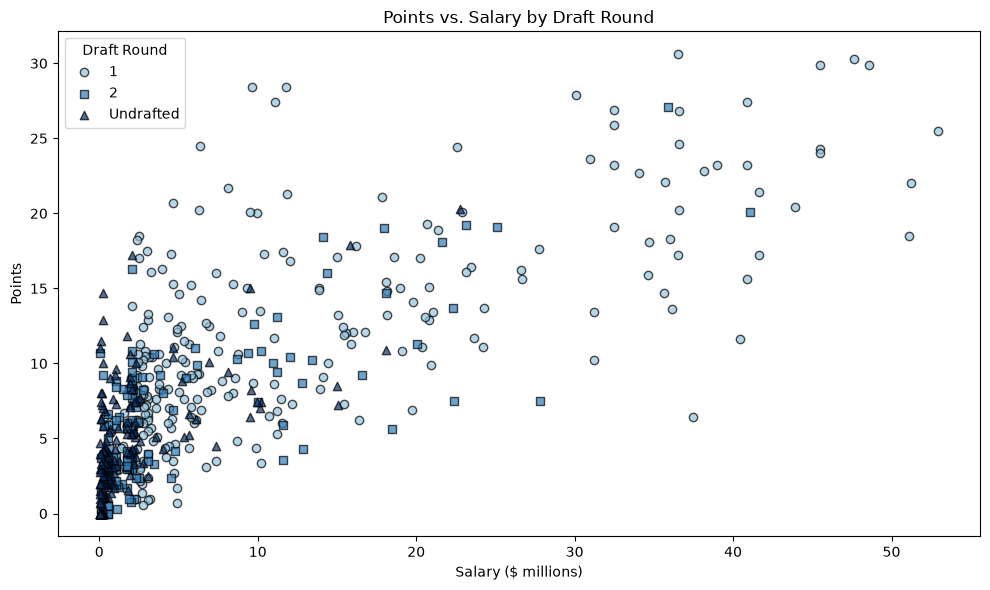

The Spearman correlation between salary and points is 0.74, a strong positive relationship.
draft round 1: average salary is 12,611,385.10 and average points is 11.73 (249 player(s))
draft round 2: average salary is 5,236,571.72 and average points is 6.64 (127 player(s))
draft round Undrafted: average salary is 1,958,909.62 and average points is 4.70 (164 player(s))


In [15]:
menu(choice=5, col1='salary', col2='points', col3='draft_round')